# Function 7 - Week 5: observation review

Review what the completed experiments have shown before using a model to choose the next query. This notebook follows the Week 4 measured-output, progress and full-input-profile pattern.

The independent Week 5 `observations.csv` contains **30 initial observations and four returned queries**, including the Week 4 return received on **23 October 2026**. Larger signed outputs are better; all 6 input settings lie in `[0, 1)`. Earlier weekly notebooks retain the evidence and reasoning available at those times.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_7/Week_05 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The four later rounds
each contain one deliberately selected query.

In [3]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 7.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 30, 1: 1, 2: 1, 3: 1, 4: 1}:
    raise ValueError("This review expects the fixed Week 5 snapshot through round 4.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 5"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,6
1,Initial observations,30
2,Returned queries,4
3,Total observations,34
4,"Queries available, including Week 5",9


Weekly queries used: 4/13


## 2. Place the latest return among the observed outputs

The Week 4 return is **2.6189682154**, ranked **1/34 (1 = highest output)**. It improves the incumbent from **2.55241765269** to **2.6189682154**, a gain of **0.0665505627101 output units**.

In [4]:
print(output_review["report"])

Latest recorded submission: round 4 (1 new output).
Compared with 33 earlier observations (34 outputs in total).
Earlier output range: [0.00270146502451, 2.55241765269].

round-04: y = 2.6189682154 (positive); rank 1/34 (1 = highest output).
Inputs: x1 = 0.002902, x2 = 0.196293, x3 = 0.424115, x4 = 0.271557, x5 = 0.287658, x6 = 0.746916
New highest observed output. Largest absolute magnitude so far (1.03 times the earlier largest).


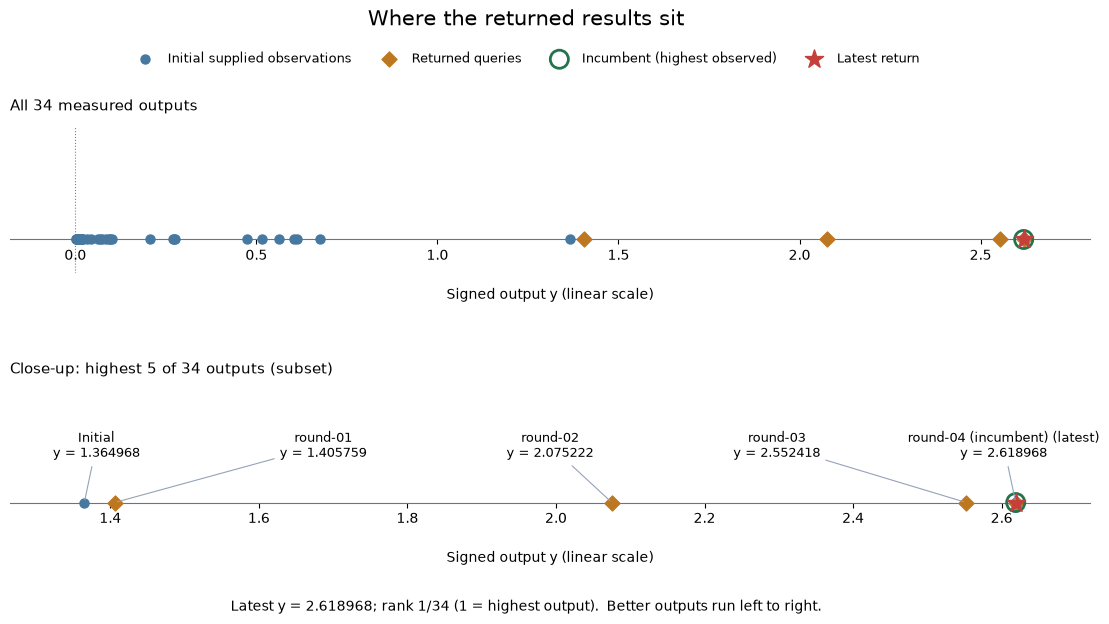

In [5]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 34 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [6]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,1.364968,—
Round 1,1.405759,1.405759,0.040791
Round 2,2.075222,2.075222,0.669463
Round 3,2.552418,2.552418,0.477196
Round 4,2.618968,2.618968,0.066551


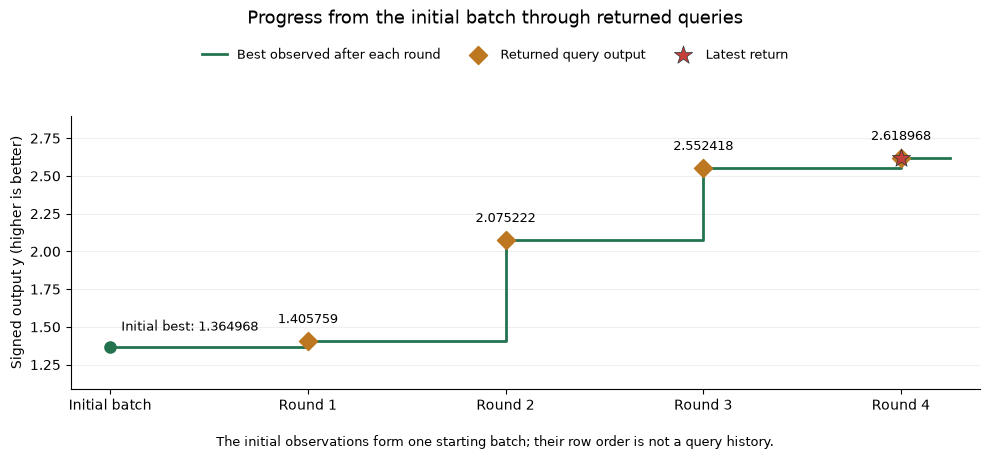

In [7]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Each of rounds 1, 2, 3 and 4 improved the incumbent. The latest gain is smaller than the gain in round 3. Four adaptive queries do not establish a convergence rate, the superiority of this method, or proximity to the unknown global maximum.

The best observed output has changed from **1.364968** in the initial batch to **2.618968**, a total gain of **1.254000 output units**. The latest return minus the previous best is **+0.066551**.

## 4. Examine the strongest input combinations

Keep all six coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [8]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,x6,y
observation_id,,,,,,,,,
round-04,1,4,0.002902,0.196293,0.424115,0.271557,0.287658,0.746916,2.618968
round-03,2,3,0.018718,0.312926,0.370268,0.285721,0.308321,0.695670,2.552418
round-02,3,2,0.015118,0.386113,0.305380,0.283890,0.363300,0.714745,2.075222
round-01,4,1,0.057896,0.491672,0.247422,0.318118,0.420428,0.730970,1.405759
initial-007,5,0,0.057896,0.491672,0.247422,0.218118,0.420428,0.730970,1.364968


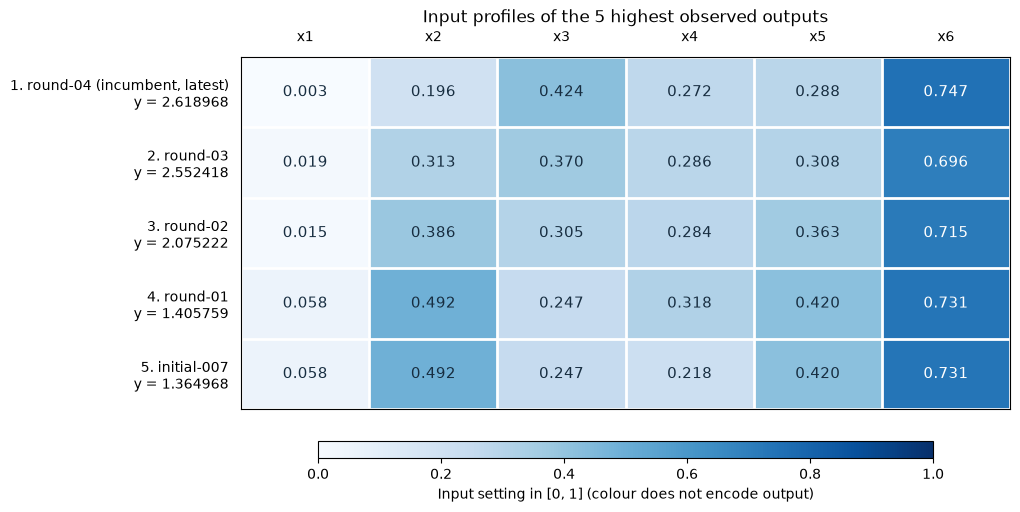

In [9]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The four returned queries are the four highest observations; the original best is now fifth. All five have **x1 below 0.06** and **x6 between 0.695670 and 0.746916**. Across the four returns, x2 and x5 decrease, x3 increases, and output rises, while other coordinates also change. This is a sequence of combinations, not a controlled test of any coordinate.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [10]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full six-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.018718,0.002902,-0.015816
x2,0.312926,0.196293,-0.116633
x3,0.370268,0.424115,0.053847
x4,0.285721,0.271557,-0.014164
x5,0.308321,0.287658,-0.020663
x6,0.695670,0.746916,0.051246


Previous best: round-03; y = 2.552418
Full six-input distance to previous best: 0.141445
Latest output minus previous best: +0.066551
Nearest earlier observation: round-03 (distance 0.141445)
Repeated full input combinations: 0


The previous best is **round-03**; its full 6-input distance from round 4 is **0.141445**. The nearest earlier observation is **round-03** (distance **0.141445**). The latest output is **0.066551 higher** than the previous best.

All coordinates share the same input range, but Euclidean distance does not account for different input relevance or predict an output change. Several settings changed together. No identical-input repeats are available to measure repeat-evaluation noise.

## 5. Carry the evidence into model review

The fourth returned query supplies a new incumbent. Review whether validation and uncertainty still support refinement of this region or exploration elsewhere. The smaller latest gain alone does not establish a taper or plateau in the unknown function.

A subsequent Week 5 model study should compare held-out prediction errors with the mean baseline, inspect uncertainty and noise sensitivity, and review candidate selection with **nine query opportunities remaining**, including Week 5.

The [saved Week 4 model notebook](../Week_04/model_predictions.ipynb) is the historical source for the submitted query and forecast. This observation review does not refit it or select a new query. Week 4 evaluation is confirmed in the [submission log](../../../submissions/README.md).

**Historical forecast check:** the [saved Week 4 model run](../Week_04/model_predictions.ipynb) predicted **2.481635** for the submitted input. The measured return was **2.618968**, or **0.137333 higher**. The saved forecast is rounded to six decimals. This comparison uses a prediction made before its answer was known; a single forecast error does not establish calibration.